# 02 Single node

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().parent
FIGURES = ANALYSIS_DIR / 'figures'
sys.path.insert(0, str(ANALYSIS_DIR))

from src.data_loader import load_iperf, load_single_node
from src.statistics import saturation_rate, slo_capacity, summarize

plt.rcParams.update(
    {
        'figure.figsize': (7, 4),
        'figure.dpi': 110,
        'savefig.dpi': 200,
        'savefig.bbox': 'tight',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.grid': True,
        'grid.alpha': 0.3,
    }
)
SINGLE, MULTI = '#2a78d6', '#eb6834'
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
SLOS_MS = [1, 10, 100]
SATURATION_TOLERANCE = 0.95

## Part 1: Network (iperf3, UDP, 10 s × 10 runs)

In [3]:
iperf = load_iperf()
net = summarize(
    iperf,
    'target_mbps',
    ['goodput_mbps', 'lost_percent', 'jitter_ms', 'client_cpu', 'server_cpu'],
)
net

,target_mbps,goodput_mbps_mean,goodput_mbps_std,goodput_mbps_ci95,goodput_mbps_n,lost_percent_mean,lost_percent_std,lost_percent_ci95,lost_percent_n,jitter_ms_mean,...,jitter_ms_ci95,jitter_ms_n,client_cpu_mean,client_cpu_std,client_cpu_ci95,client_cpu_n,server_cpu_mean,server_cpu_std,server_cpu_ci95,server_cpu_n
0,100,99.992,0.001,0.000,10,0.000,0.000,0.000,10,0.006,...,0.002,10,6.435,0.174,0.125,10,7.996,2.445,1.749,10
1,200,199.983,0.000,0.000,10,0.000,0.000,0.000,10,0.013,...,0.001,10,11.023,0.118,0.084,10,16.974,0.329,0.235,10
2,300,299.975,0.000,0.000,10,0.000,0.000,0.000,10,0.010,...,0.000,10,16.050,0.074,0.053,10,24.691,0.622,0.445,10
3,400,399.969,0.000,0.000,10,0.000,0.000,0.000,10,0.008,...,0.000,10,21.284,0.181,0.129,10,32.416,0.797,0.570,10
4,500,499.963,0.001,0.000,10,0.000,0.000,0.000,10,0.006,...,0.000,10,26.390,0.137,0.098,10,40.860,2.014,1.441,10
5,600,599.959,0.001,0.000,10,0.000,0.000,0.000,10,0.005,...,0.000,10,31.652,0.216,0.154,10,48.651,1.960,1.402,10
6,700,699.955,0.001,0.001,10,0.000,0.000,0.000,10,0.005,...,0.001,10,36.467,0.314,0.225,10,57.903,4.991,3.571,10
7,800,799.934,0.036,0.026,10,0.002,0.004,0.003,10,0.004,...,0.001,10,41.644,0.173,0.124,10,62.109,0.844,0.604,10
8,900,899.931,0.027,0.019,10,0.002,0.003,0.002,10,0.003,...,0.001,10,46.959,0.368,0.263,10,69.401,0.609,0.435,10
9,1000,934.004,47.915,34.277,10,6.593,4.791,3.427,10,0.004,...,0.001,10,50.510,2.078,1.487,10,71.402,4.265,3.051,10


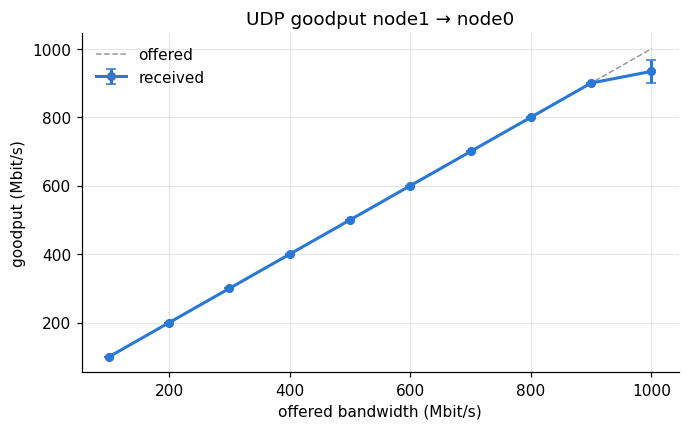

In [4]:
fig, ax = plt.subplots()
ax.plot(
    net['target_mbps'],
    net['target_mbps'],
    color='0.6',
    ls='--',
    lw=1,
    label='offered',
)
ax.errorbar(
    net['target_mbps'],
    net['goodput_mbps_mean'],
    yerr=net['goodput_mbps_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='received',
)
ax.set(
    xlabel='offered bandwidth (Mbit/s)',
    ylabel='goodput (Mbit/s)',
    title='UDP goodput node1 → node0',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_iperf_goodput.png')

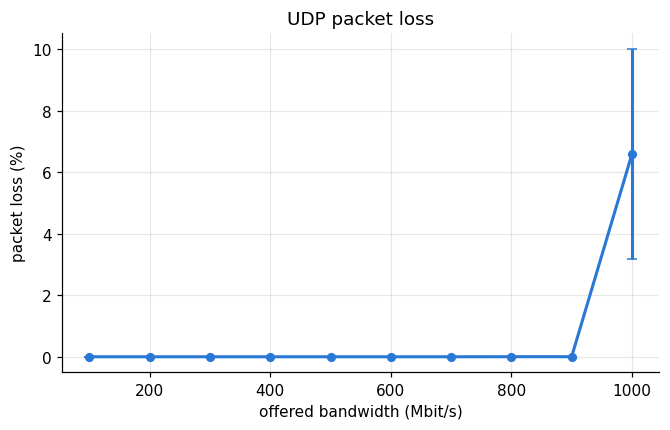

In [5]:
fig, ax = plt.subplots()
ax.errorbar(
    net['target_mbps'],
    net['lost_percent_mean'],
    yerr=net['lost_percent_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
)
ax.set(
    xlabel='offered bandwidth (Mbit/s)',
    ylabel='packet loss (%)',
    title='UDP packet loss',
)
fig.savefig(FIGURES / '02_iperf_loss.png')

## Part 2: Web server (vegeta, 30 s × 10 runs per rate)

In [6]:
single = load_single_node()
cols = [
    'achieved_rate',
    'throughput',
    'success',
    'lat_mean_ms',
    'lat_p50_ms',
    'lat_p90_ms',
    'lat_p99_ms',
    'lat_max_ms',
    'server_cpu',
    'server_usr',
    'server_sys',
]
web = summarize(single, 'rate', cols)
web[['rate'] + [c for c in web.columns if c.endswith(('_mean', '_ci95'))]]

,rate,achieved_rate_mean,achieved_rate_ci95,throughput_mean,throughput_ci95,success_mean,success_ci95,lat_mean_ms_mean,lat_mean_ms_ci95,lat_p50_ms_mean,...,lat_p99_ms_mean,lat_p99_ms_ci95,lat_max_ms_mean,lat_max_ms_ci95,server_cpu_mean,server_cpu_ci95,server_usr_mean,server_usr_ci95,server_sys_mean,server_sys_ci95
0,1000,1000.021,0.009,1000.012,0.009,1.000,0.000,0.283,0.008,0.269,...,0.585,0.011,1.677,0.264,11.275,0.834,4.728,0.710,6.547,0.817
1,2000,2000.044,0.020,2000.018,0.014,1.000,0.000,0.333,0.006,0.298,...,0.774,0.010,1.793,0.094,21.732,0.697,9.265,0.406,12.468,0.427
2,3000,3000.069,0.038,3000.036,0.035,1.000,0.000,0.398,0.013,0.354,...,0.906,0.012,1.990,0.176,31.758,1.800,13.687,1.273,18.071,1.001
3,4000,4000.027,0.055,3999.987,0.051,1.000,0.000,0.394,0.002,0.306,...,0.995,0.006,2.257,0.586,43.344,0.538,18.336,1.338,25.008,1.347
4,5000,5000.059,0.043,5000.017,0.046,1.000,0.000,0.299,0.001,0.238,...,0.888,0.019,3.227,0.628,55.562,0.438,22.911,1.804,32.651,1.611
5,6000,6000.055,0.011,6000.001,0.020,1.000,0.000,0.316,0.003,0.258,...,0.767,0.023,3.550,0.364,65.111,2.066,26.804,1.163,38.307,1.042
6,7000,7000.048,0.004,6999.996,0.013,1.000,0.000,0.280,0.003,0.214,...,0.748,0.008,4.452,0.576,48.689,0.429,20.218,0.513,28.471,0.695
7,8000,8000.025,0.017,7999.949,0.028,1.000,0.000,0.317,0.004,0.244,...,0.795,0.008,5.979,1.002,54.776,0.442,21.437,0.849,33.339,1.051
8,9000,9000.053,0.020,8999.914,0.070,1.000,0.000,0.463,0.066,0.393,...,1.761,1.103,15.183,5.808,60.661,0.348,25.272,0.507,35.389,0.514
9,10000,9999.996,0.054,9999.852,0.079,1.000,0.000,1.350,0.062,0.488,...,12.505,0.677,37.737,7.959,66.468,0.540,27.326,0.652,39.141,0.664


In [7]:
saturation = saturation_rate(web, tolerance=SATURATION_TOLERANCE)
capacity = {
    f'p99 <= {slo} ms': slo_capacity(web, 'lat_p99_ms_mean', slo)
    for slo in SLOS_MS
}
print(
    f'saturation (throughput >= {SATURATION_TOLERANCE:.0%} of offered): {saturation} req/s'
)
capacity

saturation (throughput >= 95% of offered): 18000 req/s


{'p99 <= 1 ms': 8000, 'p99 <= 10 ms': 9000, 'p99 <= 100 ms': 18000}

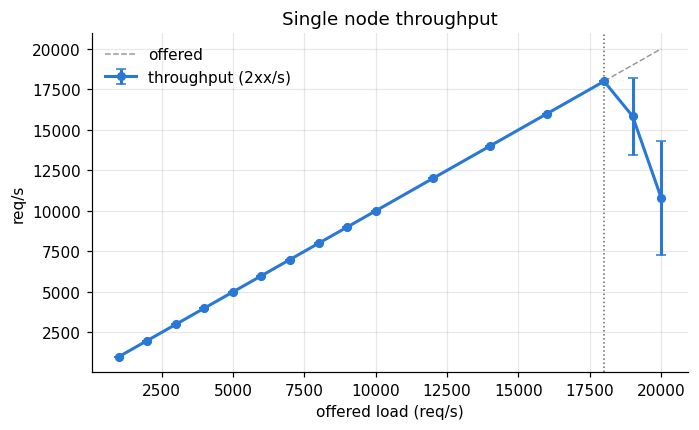

In [8]:
fig, ax = plt.subplots()
ax.plot(web['rate'], web['rate'], color='0.6', ls='--', lw=1, label='offered')
ax.errorbar(
    web['rate'],
    web['throughput_mean'],
    yerr=web['throughput_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='throughput (2xx/s)',
)
ax.axvline(saturation, color='0.4', lw=1, ls=':')
ax.annotate(
    f'saturation {saturation}',
    (saturation, 0),
    xytext=(4, 6),
    textcoords='offset points',
    color='0.3',
)
ax.set(
    xlabel='offered load (req/s)',
    ylabel='req/s',
    title='Single node throughput',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_throughput.png')

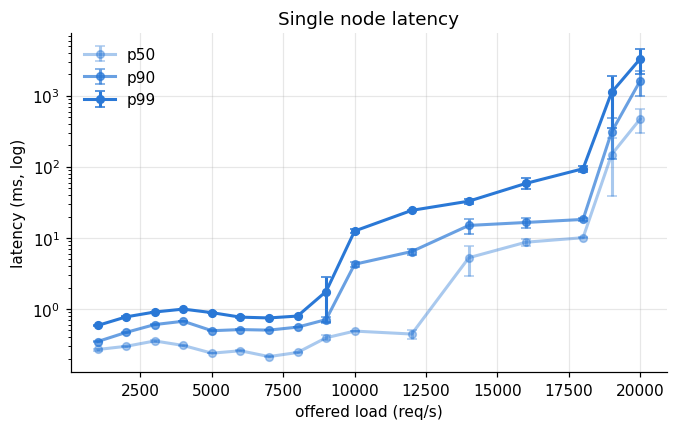

In [9]:
fig, ax = plt.subplots()
for col, shade in [
    ('lat_p50_ms', 0.4),
    ('lat_p90_ms', 0.7),
    ('lat_p99_ms', 1.0),
]:
    ax.errorbar(
        web['rate'],
        web[f'{col}_mean'],
        yerr=web[f'{col}_ci95'],
        color=SINGLE,
        alpha=shade,
        lw=2,
        marker='o',
        ms=5,
        capsize=3,
        label=col.split('_')[1],
    )
ax.set(
    yscale='log',
    xlabel='offered load (req/s)',
    ylabel='latency (ms, log)',
    title='Single node latency',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_latency.png')

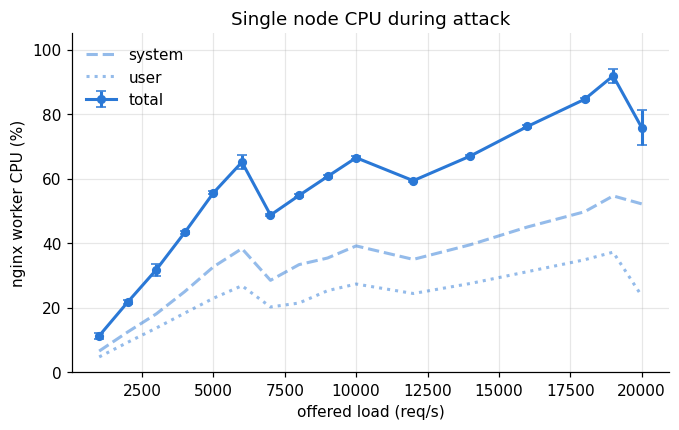

In [10]:
fig, ax = plt.subplots()
ax.errorbar(
    web['rate'],
    web['server_cpu_mean'],
    yerr=web['server_cpu_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
    label='total',
)
ax.plot(
    web['rate'],
    web['server_sys_mean'],
    color=SINGLE,
    alpha=0.5,
    lw=2,
    ls='--',
    label='system',
)
ax.plot(
    web['rate'],
    web['server_usr_mean'],
    color=SINGLE,
    alpha=0.5,
    lw=2,
    ls=':',
    label='user',
)
ax.set(
    xlabel='offered load (req/s)',
    ylabel='nginx worker CPU (%)',
    ylim=(0, 105),
    title='Single node CPU during attack',
)
ax.legend(frameon=False)
fig.savefig(FIGURES / '02_cpu.png')

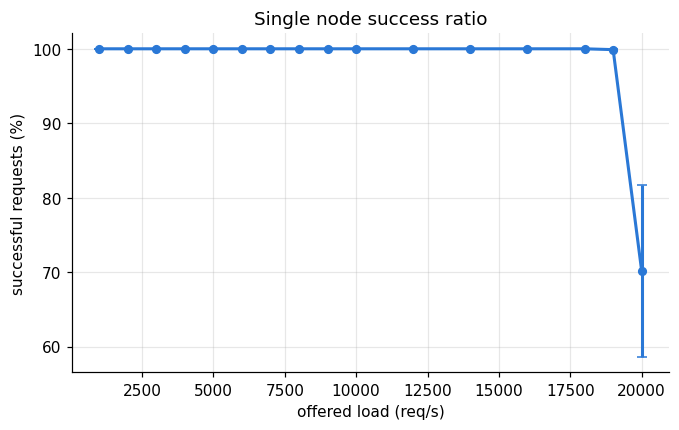

In [11]:
fig, ax = plt.subplots()
ax.errorbar(
    web['rate'],
    100 * web['success_mean'],
    yerr=100 * web['success_ci95'],
    color=SINGLE,
    lw=2,
    marker='o',
    ms=5,
    capsize=3,
)
ax.set(
    xlabel='offered load (req/s)',
    ylabel='successful requests (%)',
    title='Single node success ratio',
)
fig.savefig(FIGURES / '02_success.png')

## Is the network the bottleneck?

In [12]:
body_mbps = (
    (single['bytes_in'] * 8 / single['duration_s'] / 1e6)
    .groupby(single['rate'])
    .mean()
)
link_mbps = net['goodput_mbps_mean'].max()
pd.DataFrame({'body_mbps': body_mbps, 'share_of_link': body_mbps / link_mbps})

,body_mbps,share_of_link
rate,,
1000,4.896,0.005
2000,9.792,0.010
3000,14.688,0.016
4000,19.584,0.021
5000,24.480,0.026
6000,29.376,0.031
7000,34.272,0.037
8000,39.168,0.042
9000,44.064,0.047
